In [10]:
''' 
Simulation class creation for the simulation of EAB dynamic network in Maritime Canada

'''
import networkx as nx
import simpy
import pandas as pd
import random

In [11]:
import os

os.chdir('/..')
os.chdir('Users/alexp/OneDrive - University of New Brunswick/Grad Studies/Modelling_transport_pathways/Clean_data_sets')

os.getcwd()

'C:\\Users\\alexp\\OneDrive - University of New Brunswick\\Grad Studies\\Modelling_transport_pathways\\Clean_data_sets'

In [12]:
#Initial infected(I) vs susceptible(S) state 
def initial_state(G):
        state = {}
        for node in G.nodes:
            if node == 'Edmunston':
                state[node] = 'I'
            elif node == 'Bedford':
                state[node] = 'I'
            elif node == 'Fredericton':
                state[node] = 'I'
            elif node == 'Moncton':
                state[node] = 'I'
            elif node == 'Oromocto':
                state[node] = 'I'
            else:
                state[node] = 'S'
        nx.set_node_attributes(G,state,'State')
        return state

In [13]:
#test initial_state
#initial_state(G)

In [38]:
def state_transition(G, current_state):
    #The first generalization is that mostThe Þrst generalization is that a majority of campground visits involve relatively short travel distances (<100 km, which is usually a <2-h drive fromhome) Koch et al. 2012 
    next_state={}
    degree={}
    origin_degree={}
    num_inf_camper={}
    #Per capita value is a source of number of reservations taken from a national system 
    per_capita_value=0.0047
    #Firewood source(outside park:0.25, from home:0.17,cut of collected from another area:0.14)Jacobi et al. 2011, and Percent of live borers found in wood(0.23) Haack et al. 2010
    prob_infested_wood=(0.25+0.17+0.14)*0.23
    #Iterate through each node splitting the two by infected and uninfected nodes 
    for node in G.nodes:
        #if the node is infected, print the number of campers leaving the campground with infested wood/year(per capita value) is calculated, and calculate the total campground pull value from all campgrounds(in degree)
        
        if current_state[node] == 'I':
            
            #number of infected campers from campgrounds
            nx.set_node_attributes(G,{node:G.nodes[node]['Population']*(per_capita_value*prob_infested_wood)},'Infected_camper')
            Inf_camper = nx.get_node_attributes(G,'Infected_camper')
            
            #Get total campground pull from all neighbour nodes
            degree[node]= G.degree(node, weight='Campground_pull')
            nx.set_node_attributes(G, degree,'in_degree')
            num_inf_camper[node]=int(G.nodes[node]['Infected_camper'])
            
            #Get the pull of each campground using number of campsites in campground and distance between campground and origin
            node_degree={}
            for neighbor in G.neighbors(node):
                
                #defined variables X_i are the number of campsites, D_ij is the Distance between campground and origin
                X_i=G.nodes[neighbor]['Sites']
                D_ij=G.edges[neighbor,node]['Distance_Km']
                
                #Calculate pull value and normalize data using the total in-degree of nodes and load them into a dictionary of dictionary
                #dict : origin_degree = {Origin(node):{Campground(neighbor): normalized_pull}}
                pull = (X_i/D_ij)/degree[node]
                node_degree[neighbor]=pull
                origin_degree[node]=node_degree
    
    # create a list of randomly distributed infected campers(number of campers using k values) going from origin to a susceptible campground       
    infected=[]
    for k,v in origin_degree.items():
        infected.append(random.choices(list(v.keys()), weights=list(v.values()), k=num_inf_camper[k]))
        #flatten list
        infected_flat=[val for sublist in infected for val in sublist]
    infected_flat.sort()
    print(infected_flat)          
    
    
    
    for node in G.nodes:
        if current_state[node] == 'S':
            if node in infected_flat: 
                
    
            
            
        
            #G.edges[node]['Campground_pull']
            #random.choices(degree[node])
    #return next_state
    return Inf_camper, num_inf_camper, degree, origin_degree, 
    #return removed: Pull

    #if the node is susceptible pull data from the neighbours nodes
        #elif current_state[node] == 'S':
            #Campground_pull={}
            #node_degree={}
            #origin_degree={}
            #Get data from each neighbour of the node to calculate pull number of campsites/distance between nodes to get campground pull value
            #for neighbor in G.neighbors(node):
                
                
                #pull_dict={}
                #pull = (G.nodes[node]['Sites']/G.edges[node,neighbor]['Distance_Km'])/G.nodes[neighbor]['in_degree']
                #pull_dict['Campground_pull']=pull
                #Campground_pull[node,neighbor]=pull_dict
                
                #node_degree[node]=pull
                #origin_degree[neighbor]=node_degree
                
                
            #nx.set_edge_attributes(G, Campground_pull)
            #Pull = nx.get_edge_attributes(G, 'Campground_pull')

In [39]:
#test state transition
test_state = initial_state(G)
state_transition(G, test_state)

['Adventures East Campground & Cottages', 'All Done Camping', 'All Done Camping', 'Anchorage Provincial Park', 'Anchorage Provincial Park', 'Baddeck Cabot Trail Campground', 'Baddeck Cabot Trail Campground', 'Baddeck Cabot Trail Campground', 'BeechBrook Campground', 'BeechBrook Campground', 'BeechBrook Campground', 'BeechBrook Campground', 'BeechBrook Campground', 'BeechBrook Campground', 'BeechBrook Campground', 'BeechBrook Campground', 'BeechBrook Campground', 'Belle Baie Park', 'Ben Eoine Beach RV Resort & Campground', 'Ben Eoine Beach RV Resort & Campground', 'Birchwood Campground & Cottages', 'Borden / Summerside KOA', 'Borden / Summerside KOA', 'Bouctouche Baie', 'Bouctouche Baie', 'Bouctouche Baie', "Bras d'Or Lakes Campground", 'Cabot Beach Provincial Park', 'Cabot Beach Provincial Park', 'Cambridge Narrows', "Camper's City RV Resort", "Camper's City RV Resort", "Camper's City RV Resort", "Camper's City RV Resort", "Camper's Haven Campground", "Camper's Haven Campground", 'Camp

({'Bedford': 244.03938216000003,
  'Edmunston': 7.316380960000001,
  'Fredericton': 35.2440592,
  'Moncton': 43.51872504000001,
  'Oromocto': 5.583235280000001},
 {'Bedford': 244,
  'Edmunston': 7,
  'Fredericton': 35,
  'Moncton': 43,
  'Oromocto': 5},
 {'Bedford': 225,
  'Edmunston': 225,
  'Fredericton': 225,
  'Moncton': 225,
  'Oromocto': 225},
 {'Bedford': {'ADDA Fundy Tides CG- City': 0.0006930814453258119,
   'Adventures East Campground & Cottages': 0.0011354703242508887,
   'All Done Camping': 0.0006517909649594464,
   'All Points East Campground': 0.000452409669405848,
   'Amherst Shore Provincial Park': 0.0009749856820305764,
   'Anchorage Provincial Park': 0.0010901326287290586,
   'Arm of Gold Campgrounds': 0.0,
   'Armstrong Brook-Mount Carleton Provincial Park': 0.0007290548359330945,
   'Baddeck Cabot Trail Campground': 0.0025325528192953173,
   'Battery Provincial Park': 0.0007534157951485085,
   'Bayside RV Campground': 0.0,
   'Bear Falls Wilderness Campground': 0.00

In [24]:
#import dataframes
#gravity_df=pd.read_csv('Campground_origin_data_raw.csv',index_col=0)
edge_df=pd.read_csv('edge_dataframe.csv',index_col=0)
node_df=pd.read_csv('node_dataframe.csv',index_col=0)
#convert dataframe to edgelist
G=nx.from_pandas_edgelist(edge_df,source='Origin',target='Campground',edge_attr=['Distance_Km'])
#add node attributes to edgelist
nx.set_node_attributes(G,dict(zip(node_df['Name'],node_df['Population'])),'Population')
nx.set_node_attributes(G, dict(zip(node_df['Name'],node_df['Sites'])),'Sites')

In [17]:
#The first generalization is that that a majority of campground visits involve relatively short travel distances (<100 km, which is usually a <2-h drive fromhome) Koch et al. 2012 
current_state = G  

next_state={}
per_capita_value=0.0047
#Firewood source(outside park:0.25, from home:0.17,cut of collected from another area:0.14)Jacobi et al. 2011, and Percent of live borers found in wood(0.23) Haack et al. 2010
prob_infested_wood=(0.25+0.17+0.14)*0.23
#list through going node by node to check for the current state to see the probability of a 
for node in G.nodes:
    Infected_camper=[]
    if current_state[node] == 'I':
        nx.set_node_attributes(G,{node:G.nodes[node]['Population']*(per_capita_value*prob_infested_wood)},'Infected_camper')
        nx.get_node_attributes(node,'Infected_camper')
    #if current_state[node] == 'S':
#for node in G.nodes:
    #for node in G.edges:
    #nx.get_edge_attributes
    

In [167]:
import networkx as nx

sim=simulation_EAB()
sim.initial_state(G)

TypeError: __init__() missing 1 required positional argument: 'G'

In [18]:
#nx.get_node_attributes(G,'Sites')
#dict(zip(node_df['Name'],node_df['Population']))
#pd.Series(node_df['Population'],index=node_df.Name)
G.nodes['Fredericton']['Population']

58220

TypeError: draw_networkx_edge_labels() missing 1 required positional argument: 'pos'

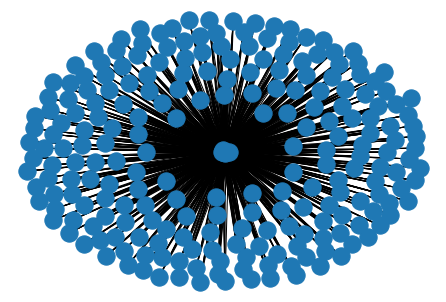

In [17]:
'Draw Graph'
#need to add positions to the edgelist of nodes
nx.draw(G)
edge_label=nx.get_edge_attributes(G,'Distance_km')
node_label=nx.get_edge_attributes(G,'campsites')
nx.draw_networkx_edge_labels(G, edge_labels=edge_label)
